In [ ]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time


def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.01), initial_p_range=(3.2, 3.5)):
    """生成维护计划（保持不变）"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values

# 🔥 🔥 🔥 从代码2复制的核心函数：计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 🔥 🔥 从代码2复制的核心聚类函数（完全替换）
def clustering_CR(df_window, window_size, window_start, global_task_count=None, full_df=None, D_min_dict=None, D_max_dict=None):
    """代码2的Gurobi版本 - 完全替换原函数"""
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 任务分配约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # 容量约束
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # 时间窗口约束
    a = [0] * N
    b = [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # 聚类激活约束
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # 🔥 关键差异1：新的目标函数（最大化利润 = setup_cost - CP_total）
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    
    # CP成本矩阵
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    obj = setup_cost - CP_total  # 🔥 最大化利润
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # 🔥 关键差异2：新增维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            
            prev_rows = full_df[
                (full_df['CSEM'] == caisson) &
                (full_df['CENTER'] < row['DATE']) &
                (full_df['OPERATION'] == 'x')
            ].sort_values('CENTER')
            
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # 求解参数
    mdl.setParam('LogToConsole', 1)
    mdl.setParam('OutputFlag', 1)
    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    # 结果提取
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].x
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal}")
    return df_window

# 🔥 保持原有的泄漏计算函数不变
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
            
        alpha = alpha_values[int(csem)]

        # 任务间泄漏
        for i in range(1, len(x_operations)):
            current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
            prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
            center_diff = current_time - prev_time - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']

        # 开头泄漏
        first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
        total_leakage += first_time * alpha * PARAMS['K']

        # 结尾泄漏
        last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
        leak_time = max(0, T - (last_time + 1))
        total_leakage += leak_time * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time (使用代码2的逻辑）"""
    for caisson in clustered_df["CSEM"].unique():
        # 当前 caisson 在当前窗口内的 x 任务
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) > 1:
            # 第二个任务的 index（保持代码2逻辑）
            second_idx = tasks.index[1]
            
            # 该 caisson 在本窗口聚类后的中心时间
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # 按代码2方式计算新的日期
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            
            # 同时更新 DATE 和 CENTER
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date


# 🔥 主函数修改：集成代码2逻辑
def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数 - 修改版"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # 🔥 新增：计算维修周期约束（代码2特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # CPU时间测量
    clustering_cpu_start = time.process_time()
    
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # 🔥 使用新的clustering_CR（带维护约束）
        clustered_df = clustering_CR(
            first_tasks, window_size, window_start, 
            full_df=df, D_min_dict=D_min_dict, D_max_dict=D_max_dict
        )
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑（保持不变）
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏（保持不变）
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }

def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats


def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df


def visualize_clustering_results(result_dict, params, seed_name="default", save_csv=True, show_plot=True):
    """可视化聚类结果"""
    result_df = result_dict['final_df']
    maintenance_plan = result_dict['maintenance_plan']
    
    # 成本计算
    operation_x_count = (result_df['OPERATION'] == 'x').sum()
    before_cost = operation_x_count * params['Cs'] 
    operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
    after_cost = operation_x_center_unique_count * params['Cs'] 
    
    print(f"Cost before grouping: {before_cost}")
    print(f"Cost after grouping: {after_cost}")
    
    # 泄漏统计
    leakage_before = round(result_dict['leakage_before'], 3)
    leakage_after = round(result_dict['leakage_after'], 3)
    print(f"Gas leakage before: {leakage_before}")
    print(f"Gas leakage after: {leakage_after}")
    
    # 节约统计
    cost_reduction = before_cost - after_cost
    cost_reduction_pct = (cost_reduction / before_cost * 100) if before_cost > 0 else 0
    print(f"Cost reduction: {cost_reduction} ({cost_reduction_pct:.1f}%)")
    print(f"Gas leakage reduction: {result_dict['reduction']:.3f} ({result_dict['reduction_pct']:.1f}%)")
    
    # 计算统计指标（修复UnboundLocalError）
    result_df_x_count = len(result_df[result_df['OPERATION'] == 'x'])
    avg_tasks_per_cluster = result_df_x_count / operation_x_center_unique_count if operation_x_center_unique_count > 0 else 0
    
    if show_plot:
        plt.figure(figsize=(8, 7))
        
        df_original_x = maintenance_plan[maintenance_plan['OPERATION'] == 'x']
        result_df_x = result_df[result_df['OPERATION'] == 'x']
        
        df_x = df_original_x.set_index('INDEX')
        result_x = result_df_x.set_index('INDEX')
        common_indices = df_x.index.intersection(result_x.index)
        df_x = df_x.loc[common_indices].reset_index()
        result_x = result_x.loc[common_indices].reset_index()
        
        time_shift = result_x['CENTER'] - df_x['DATE']
        plt.scatter(df_x['DATE'], result_x['CENTER'], 
                   c=time_shift, cmap='RdBu_r', 
                   vmin=-max(abs(time_shift.min()), abs(time_shift.max())), 
                   vmax=max(abs(time_shift.min()), abs(time_shift.max())), 
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.8)
        
        plt.colorbar(label='Time Shift (days)\nRed=delayed, Blue=advanced')
        plt.title(f"Cluster Center Distribution (Seed {seed_name})", fontsize=16, fontweight='bold')
        plt.xlabel("Original time", fontsize=14)
        plt.ylabel("Cluster center", fontsize=14)
        plt.grid(True, alpha=0.3)
        
        max_range = max(result_x['DATE'].max(), result_x['CENTER'].max() + 5)
        plt.xlim(0, max_range)
        plt.ylim(0, max_range)
        plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', linewidth=2, label='45° diagonal')
        plt.legend()
        plt.gca().set_aspect('equal')
        plt.tight_layout()
        plt.show()
        
        center_counts = result_df_x['CENTER'].value_counts().sort_index()
        print("\nCluster center usage:")
        print(center_counts)
        print(f"Total clusters used: {len(center_counts)}")
        print(f"Average tasks per cluster: {avg_tasks_per_cluster:.1f}")
    
    if save_csv:
        filename = f'optimized_plan_seed_{seed_name}.csv'
        result_df.to_csv(filename, index=False)
        print(f"\nResult saved to '{filename}'")
    
    print(f"\nSummary:")
    print(f"- Cost saved: {cost_reduction_pct:.1f}%")
    print(f"- Gas leakage reduced: {result_dict['reduction_pct']:.1f}%")
    print(f"- Clusters created: {operation_x_center_unique_count}")


    return {
        'before_cost': before_cost,
        'after_cost': after_cost,
        'cost_reduction': cost_reduction,
        'cost_reduction_pct': cost_reduction_pct,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'clusters_used': operation_x_center_unique_count,
        'avg_tasks_per_cluster': avg_tasks_per_cluster
    }

# # 使用示例 - 生成你的表格CSV if we fixed P and iterate seeds
# PARAMS = {
#     'P': 100, 
#     'T': 180, 
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100}

# seeds_to_test = [40]

# # name the file if sensitivity for P
# detailed_results_df = run_analysis_with_csv_export(
#     PARAMS, seeds_to_test, 
#     output_filename=f'cost{PARAMS["P"]}.csv'
# )

# # 显示前几行
# print("\n📋 CSV预览:")
# print(detailed_results_df.round(3).head())
# visualize_clustering_results(
#     run_clustering_analysis(PARAMS, random_seed=40),
#     PARAMS, seed_name=40, save_csv=False, show_plot=True)



# 🔥 新实验：固定seed=1，P从10-200循环
# seed = 6  # 固定单一seed
# P_values = list(range(10, 201, 10))  # 10,20,...,200，共19个值

# base_params = {
#     'T': 180, 
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100
# }

# all_results = []

# for p in P_values:
#     print(f"\n🔄 Running P={p} with seed={seed}...")
    
#     params = base_params.copy()
#     params['P'] = p  # 更新P
    
#     # 运行分析（单seed）
#     result_dict = run_clustering_analysis(params, random_seed=seed)
#     stats = calculate_detailed_stats(result_dict, params)
#     stats['seed'] = seed
#     stats['P'] = p  # 添加P列
    
#     all_results.append(stats)
    
#     print(f"✅ P={p}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")

# # DataFrame并保存
# results_df = pd.DataFrame(all_results)

# # 🔥 你以前的精确列顺序（从CSV头）
# original_column_order = [
#     'seed', 'nb_groups', 'Avg_tasks/group', 
#     'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#     'Avg_shift_(abs)', 'Max_shift_(abs)', 
#     'Avg_advance_(days)', 'Avg_delay_(days)', 
#     'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#     'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 
#     'total_clustering_cpu_s'
# ]

# # 🔥 P放最前，其余严格按原顺序
# column_order = ['P'] + original_column_order
# available_columns = [col for col in column_order if col in results_df.columns]
# results_df = results_df[available_columns]

# filename = f'Sensitivity_P10-200_seed{seed}_all_metrics.csv'
# results_df.to_csv(filename, index=False, float_format='%.3f')
# print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")

# # 显示预览
# print("\n📋 结果预览:")
# print(results_df.round(3)[['P', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))

# # 可视化最后一个P的结果
# visualize_clustering_results(
#     run_clustering_analysis({**base_params, 'P': 200}, random_seed=seed),
#     {**base_params, 'P': 200}, seed_name=f"{seed}_P200", save_csv=True)




# # 🔥 新实验：固定seed=1，P从10-200循环
# for seed in range(7, 31):  
#     P_values = list(range(10, 201, 10))  # 10,20,...,200，共19个值

#     base_params = {
#         'T': 180, 
#         'Cmax': 20, 
#         'window_size': 10, 
#         'advanced': 3, 
#         'K': 5.993, 
#         'Calpha': 5, 
#         'Cbeta': 10, 
#         'Cs': 100
#     }

#     all_results = []

#     for p in P_values:
#         print(f"\n🔄 Running P={p} with seed={seed}...")
        
#         params = base_params.copy()
#         params['P'] = p  # 更新P
        
#         # 运行分析（单seed）
#         result_dict = run_clustering_analysis(params, random_seed=seed)
#         stats = calculate_detailed_stats(result_dict, params)
#         stats['seed'] = seed
#         stats['P'] = p  # 添加P列
        
#         all_results.append(stats)
        
#         print(f"✅ P={p}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")

#     # DataFrame并保存
#     results_df = pd.DataFrame(all_results)

#     # 🔥 你以前的精确列顺序（从CSV头）
#     original_column_order = [
#         'seed', 'nb_groups', 'Avg_tasks/group', 
#         'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#         'Avg_shift_(abs)', 'Max_shift_(abs)', 
#         'Avg_advance_(days)', 'Avg_delay_(days)', 
#         'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#         'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 
#         'total_clustering_cpu_s'
#     ]

#     # 🔥 P放最前，其余严格按原顺序
#     column_order = ['P'] + original_column_order
#     available_columns = [col for col in column_order if col in results_df.columns]
#     results_df = results_df[available_columns]

#     filename = f'Sensitivity_P10-200_seed{seed}_all_metrics.csv'
#     results_df.to_csv(filename, index=False, float_format='%.3f')
#     print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")

#     # 显示预览
#     print("\n📋 结果预览:")
#     print(results_df.round(3)[['P', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))

#     # 可视化最后一个P的结果
#     visualize_clustering_results(
#         run_clustering_analysis({**base_params, 'P': 200}, random_seed=seed),
#         {**base_params, 'P': 200}, seed_name=f"{seed}_P200", save_csv=True)



# # 🔥 新实验：固定seed=1，T从10-200循环
# for seed in range(1, 31):
#     T_values = list(range(30, 361, 30))  # 30,60,...,360，共12个值

#     base_params = {
#         'P': 100, 
#         'Cmax': 20, 
#         'window_size': 10, 
#         'advanced': 3, 
#         'K': 5.993, 
#         'Calpha': 5, 
#         'Cbeta': 10, 
#         'Cs': 100
#     }

#     all_results = []

#     for t in T_values:
#         print(f"\n🔄 Running T={t} with seed={seed}...")
        
#         params = base_params.copy()
#         params['T'] = t  # 更新T
        
#         # 运行分析（单seed）
#         result_dict = run_clustering_analysis(params, random_seed=seed)
#         stats = calculate_detailed_stats(result_dict, params)
#         stats['seed'] = seed
#         stats['T'] = t  # 添加T列
        
#         all_results.append(stats)
        
#         print(f"✅ T={t}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")

#     # DataFrame并保存
#     results_df = pd.DataFrame(all_results)

#     # 🔥 你以前的精确列顺序（从CSV头）
#     original_column_order = [
#         'seed', 'nb_groups', 'Avg_tasks/group', 
#         'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#         'Avg_shift_(abs)', 'Max_shift_(abs)', 
#         'Avg_advance_(days)', 'Avg_delay_(days)', 
#         'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#         'leakage_before', 'leakage_after', 'leakage_reduction', 'leakage_reduction_pct', 
#         'total_clustering_cpu_s'
#     ]

#     # 🔥 P放最前，其余严格按原顺序
#     column_order = ['T'] + original_column_order
#     available_columns = [col for col in column_order if col in results_df.columns]
#     results_df = results_df[available_columns]

#     filename = f'Sensitivity_T30-360_seed{seed}_all_metrics.csv'
#     results_df.to_csv(filename, index=False, float_format='%.3f')
#     print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")

#     # 显示预览
#     print("\n📋 结果预览:")
#     print(results_df.round(3)[['T', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))

#     # 可视化最后一个P的结果
#     visualize_clustering_results(
#         run_clustering_analysis({**base_params, 'T': 360}, random_seed=seed),
#         {**base_params, 'T': 360}, seed_name=f"{seed}_T360", save_csv=True)




import time
import threading
import pandas as pd  # 确保导入

# 🔥 配置（你的原始参数）
P_values = list(range(10, 201, 10))
PARAMS = {
    'T': 180, 
    'Cmax': 20, 
    'window_size': 10, 
    'advanced': 3, 
    'K': 5.993, 
    'Calpha': 5, 
    'Cbeta': 10, 
    'Cs': 100
}

TIMEOUT_SECONDS_PER_SEED = 180  # 3分钟
MAX_ATTEMPTS = 50
TARGET_SEEDS = 30

class SeedTimeoutException(Exception):
    pass

def seed_timeout_monitor(stop_event):
    time.sleep(TIMEOUT_SECONDS_PER_SEED)
    stop_event.set()
    raise SeedTimeoutException("Seed超时3分钟")

# 🔥 初始化变量
successful_count = 0

print(f"🚀 Seed超时保护版 - 目标{ TARGET_SEEDS }个完整结果")

# 🔥 你的原始循环结构 + 超时保护
for seed_attempt in range(MAX_ATTEMPTS):
    if successful_count >= TARGET_SEEDS:
        break
        
    seed = seed_attempt + 1
    print(f"\n🔄 Processing seed {seed}... (总超时3min)")
    
    # 🔥 Seed超时监控
    stop_event = threading.Event()
    timeout_thread = threading.Thread(target=seed_timeout_monitor, args=(stop_event,))
    timeout_thread.daemon = True
    timeout_thread.start()
    
    all_results = []
    seed_success = True
    
    try:
        for p in P_values:
            if stop_event.is_set():
                print(f"\n⏰ Seed={seed} 总超时3分钟，换下一个seed！")
                seed_success = False
                break
            
            print(f"\n🔄 Running P={p} with seed={seed}...")
            
            params = PARAMS.copy()
            params['P'] = p
            
            # 🔥 无P超时，直接运行你的函数
            result_dict = run_clustering_analysis(params, random_seed=seed)
            stats = calculate_detailed_stats(result_dict, params)
            stats['seed'] = seed
            stats['P'] = p
            all_results.append(stats)
            
            print(f"✅ P={p}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
        
        # 🔥 停止超时线程
        stop_event.set()
        timeout_thread.join(timeout=1)
        
        if seed_success and len(all_results) == len(P_values):
            # 🔥 🔥 🔥 完全你的原始保存逻辑！
            results_df = pd.DataFrame(all_results)
            
            # 🔥 你以前的精确列顺序
            original_column_order = [
                'seed', 'nb_groups', 'Avg_tasks/group', 
                'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
                'Avg_shift_(abs)', 'Max_shift_(abs)', 
                'Avg_advance_(days)', 'Avg_delay_(days)', 
                'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
                'leakage_before', 'leakage_after', 'leakage_reduction', 
                'leakage_reduction_pct', 'total_clustering_cpu_s'
            ]
            
            # 🔥 P放最前，完全一样！
            column_order = ['P'] + original_column_order
            available_columns = [col for col in column_order if col in results_df.columns]
            results_df = results_df[available_columns]
            
            # 🔥 🔥 完全一样的文件名！
            filename = f'Sensitivity_P_COST/Sensitivity_P10-200_seed{seed}_COST.csv'
            results_df.to_csv(filename, index=False, float_format='%.3f')
            print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")
            
            # 🔥 你的预览，完全一样！
            print("\n📋 结果预览:")
            print(results_df.round(3)[['P', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))
            
            # # 🔥 你的可视化，完全一样！
            # visualize_clustering_results(
            #     run_clustering_analysis({**PARAMS, 'P': 200}, random_seed=seed),
            #     {**PARAMS, 'P': 200}, seed_name=f"{seed}_P200", save_csv=True
            # )
            
            successful_count += 1
            print(f"✅ Seed={seed} 完美！进度：{successful_count}/{TARGET_SEEDS}")
        else:
            print(f"❌ Seed={seed} 超时中断，尝试下一个...")
            
    except Exception as e:
        print(f"💥 Seed={seed} 异常：{str(e)}")
        stop_event.set()
        timeout_thread.join(timeout=1)

print(f"\n🎉 批量实验完成！成功{successful_count}/{TARGET_SEEDS}个seed")



# import time
# import threading
# import pandas as pd  # 确保导入


# # 🔥 配置（修改：固定P=100，T从30-360每隔30）
# T_values = list(range(30, 361, 30))  # 30,60,90,...,360
# PARAMS = {  # 🔥 改名为 PARAMS
#     'P': 100,  
#     'Cmax': 20, 
#     'window_size': 10, 
#     'advanced': 3, 
#     'K': 5.993, 
#     'Calpha': 5, 
#     'Cbeta': 10, 
#     'Cs': 100
# }


# TIMEOUT_SECONDS_PER_SEED = 180  # 3分钟
# MAX_ATTEMPTS = 50
# TARGET_SEEDS = 30


# class SeedTimeoutException(Exception):
#     pass


# def seed_timeout_monitor(stop_event):
#     time.sleep(TIMEOUT_SECONDS_PER_SEED)
#     stop_event.set()
#     raise SeedTimeoutException("Seed超时3分钟")


# # 🔥 初始化变量
# successful_count = 0


# print(f"🚀 Seed超时保护版 - 固定P=100，T=30-360 - 目标{ TARGET_SEEDS }个完整结果")


# # 🔥 你的原始循环结构 + 超时保护
# for seed_attempt in range(MAX_ATTEMPTS):
#     if successful_count >= TARGET_SEEDS:
#         break
        
#     seed = seed_attempt + 1
#     print(f"\n🔄 Processing seed {seed}... (总超时3min)")
    
#     # 🔥 Seed超时监控
#     stop_event = threading.Event()
#     timeout_thread = threading.Thread(target=seed_timeout_monitor, args=(stop_event,))
#     timeout_thread.daemon = True
#     timeout_thread.start()
    
#     all_results = []
#     seed_success = True
    
#     try:
#         for t in T_values:
#             if stop_event.is_set():
#                 print(f"\n⏰ Seed={seed} 总超时3分钟，换下一个seed！")
#                 seed_success = False
#                 break
            
#             print(f"\n🔄 Running T={t} with seed={seed}...")
            
#             params = PARAMS.copy()
#             params['T'] = t
            
#             # 🔥 无T超时，直接运行你的函数
#             result_dict = run_clustering_analysis(params, random_seed=seed)
#             stats = calculate_detailed_stats(result_dict, params)
#             stats['seed'] = seed
#             stats['T'] = t  # 修改为T
#             all_results.append(stats)
            
#             print(f"✅ T={t}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
        
#         # 🔥 停止超时线程
#         stop_event.set()
#         timeout_thread.join(timeout=1)
        
#         if seed_success and len(all_results) == len(T_values):
#             # 🔥 🔥 🔥 完全你的原始保存逻辑！
#             results_df = pd.DataFrame(all_results)
            
#             # 🔥 你以前的精确列顺序（添加T）
#             original_column_order = [
#                 'seed', 'nb_groups', 'Avg_tasks/group', 
#                 'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost', 
#                 'Avg_shift_(abs)', 'Max_shift_(abs)', 
#                 'Avg_advance_(days)', 'Avg_delay_(days)', 
#                 'pct_advanced_%', 'pct_delayed_%', 'pct_unchanged_%', 
#                 'leakage_before', 'leakage_after', 'leakage_reduction', 
#                 'leakage_reduction_pct', 'total_clustering_cpu_s'
#             ]
            
#             # 🔥 T放最前，完全一样！
#             column_order = ['T'] + original_column_order  # 修改为T
#             available_columns = [col for col in column_order if col in results_df.columns]
#             results_df = results_df[available_columns]
            
#             # 🔥 🔥 修改文件名：Sensitivity_T_MIMAR
#             filename = f'Sensitivity_T_COST/Sensitivity_T30-360_seed{seed}_COST.csv'
#             results_df.to_csv(filename, index=False, float_format='%.3f')
#             print(f"\n📁 结果保存到: {filename} (共{len(results_df)}行，{len(results_df.columns)}列)")
            
#             # 🔥 你的预览，显示T列
#             print("\n📋 结果预览:")
#             print(results_df.round(3)[['T', 'nb_groups', 'CP_cost', 'Total_cost', 'total_clustering_cpu_s']].head(10))
            
#             successful_count += 1
#             print(f"✅ Seed={seed} 完美！进度：{successful_count}/{TARGET_SEEDS}")
#         else:
#             print(f"❌ Seed={seed} 超时中断，尝试下一个...")
            
#     except Exception as e:
#         print(f"💥 Seed={seed} 异常：{str(e)}")
#         stop_event.set()
#         timeout_thread.join(timeout=1)


# print(f"\n🎉 批量实验完成！成功{successful_count}/{TARGET_SEEDS}个seed")




🚀 Seed超时保护版 - 固定P=100，T=30-360 - 目标30个完整结果

🔄 Processing seed 1... (总超时3min)

🔄 Running T=30 with seed=1...
Generated 52 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
2          ... 10.00        ...
3          ... 10.00        ...
6          ... 10.00        ...
7          ... 10.00        ...
10         ... 10.00        ...
11         ... 10.00        ...
12         ... 10.00        ...
17         ... 10.00        ...
18         ... 10.00        ...
20         ... 10.00        ...
21         ... 10.00        ...
22         ... 10.00        ...
23         ... 10.00        ...
28         ... 10.00        ...
29         ... 10.00        ...
31         ... 10.00        ...
40         ... 10.00        ...
41         ... 10.00        ...
45         ... 10.00        ...
46         ... 10.00        ...
48         ... 10.00        ...
49     

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 10: N_tasks=20
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 497 rows, 242 columns and 1362 nonzeros
Model fingerprint: 0xd815caf5
Variable types: 11 continuous, 231 integer (231 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 935.0000000
Presolve removed 455 rows and 81 columns
Presolve time: 0.00s
Presolved: 42 rows, 161 columns, 472 nonzeros
Variable types: 0 continuous, 161 integer (161 binary)
Found heuristic solution: objective 1300.0000000

Root relaxation: objective 1.753367e+03, 20 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Une

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 10: N_tasks=20
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 497 rows, 242 columns and 1362 nonzeros
Model fingerprint: 0x7abf048c
Variable types: 11 continuous, 231 integer (231 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+01]
Presolve removed 453 rows and 71 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 10: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to valu

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (2,182 outputs left out)


Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 340: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 350: N_tasks=22
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 583 rows, 264 columns and 1892 nonzeros
Model fingerprint: 0xaea090ea
Variable types: 11 continuous, 253 integer (253 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [1e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+01]
Found heuristic solution: objective 1070.0000000
Presolve removed 539 rows and 81 columns
Presolve time: 0.00s
Presolved: 44 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py:293: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])



📁 结果保存到: Sensitivity_T_COST/Sensitivity_T30-360_seed30_COST.csv (共12行，20列)

📋 结果预览:
     T  nb_groups  CP_cost  Total_cost  total_clustering_cpu_s
0   30          6      475        1075                   0.176
1   60         25      590        3090                   0.260
2   90         42      640        4840                   0.362
3  120         58      875        6675                   0.411
4  150         70     1220        8220                   0.613
5  180         89     1315       10215                   0.801
6  210        101     1565       11665                   0.910
7  240        112     1925       13125                   1.010
8  270        130     2070       15070                   1.181
9  300        143     2350       16650                   1.232
✅ Seed=30 完美！进度：30/30

🎉 批量实验完成！成功30/30个seed


Exception in thread Thread-47:
Traceback (most recent call last):
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/threading.py", line 980, in _bootstrap_inner
    self.run()
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/threading.py", line 917, in run
    self._target(*self._args, **self._kwargs)
  File "/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_35373/476180714.py", line 980, in seed_timeout_monitor
__main__.SeedTimeoutException: Seed超时3分钟
Exception in thread Thread-48:
Traceback (most recent call last):
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/threading.py", line 980, in _bootstrap_inner
    self.run()
  File "/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "/Use

In [7]:
# sensitivity for alpha: P=100, T=180
import os

import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time


def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.01), initial_p_range=(3.2, 3.5)):
    """生成维护计划（保持不变）"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values

# 🔥 🔥 🔥 从代码2复制的核心函数：计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 🔥 🔥 从代码2复制的核心聚类函数（完全替换）
def clustering_CR(df_window, window_size, window_start, global_task_count=None, full_df=None, D_min_dict=None, D_max_dict=None):
    """代码2的Gurobi版本 - 完全替换原函数"""
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 任务分配约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # 容量约束
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # 时间窗口约束
    a = [0] * N
    b = [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # 聚类激活约束
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # 🔥 关键差异1：新的目标函数（最大化利润 = setup_cost - CP_total）
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    
    # CP成本矩阵
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    obj = setup_cost - CP_total  # 🔥 最大化利润
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # 🔥 关键差异2：新增维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            
            prev_rows = full_df[
                (full_df['CSEM'] == caisson) &
                (full_df['CENTER'] < row['DATE']) &
                (full_df['OPERATION'] == 'x')
            ].sort_values('CENTER')
            
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # 求解参数
    mdl.setParam('LogToConsole', 1)
    mdl.setParam('OutputFlag', 1)
    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    # 结果提取
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].x
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal}")
    return df_window

# 🔥 保持原有的泄漏计算函数不变
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
            
        alpha = alpha_values[int(csem)]

        # 任务间泄漏
        for i in range(1, len(x_operations)):
            current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
            prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
            center_diff = current_time - prev_time - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']

        # 开头泄漏
        first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
        total_leakage += first_time * alpha * PARAMS['K']

        # 结尾泄漏
        last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
        leak_time = max(0, T - (last_time + 1))
        total_leakage += leak_time * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time (使用代码2的逻辑）"""
    for caisson in clustered_df["CSEM"].unique():
        # 当前 caisson 在当前窗口内的 x 任务
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) > 1:
            # 第二个任务的 index（保持代码2逻辑）
            second_idx = tasks.index[1]
            
            # 该 caisson 在本窗口聚类后的中心时间
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # 按代码2方式计算新的日期
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            
            # 同时更新 DATE 和 CENTER
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date


# 🔥 主函数修改：集成代码2逻辑
def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数 - 修改版"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # 🔥 新增：计算维修周期约束（代码2特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # CPU时间测量
    clustering_cpu_start = time.process_time()
    
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # 🔥 使用新的clustering_CR（带维护约束）
        clustered_df = clustering_CR(
            first_tasks, window_size, window_start, 
            full_df=df, D_min_dict=D_min_dict, D_max_dict=D_max_dict
        )
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑（保持不变）
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏（保持不变）
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }

def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats


def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df


def visualize_clustering_results(result_dict, params, seed_name="default", save_csv=True, show_plot=True):
    """可视化聚类结果"""
    result_df = result_dict['final_df']
    maintenance_plan = result_dict['maintenance_plan']
    
    # 成本计算
    operation_x_count = (result_df['OPERATION'] == 'x').sum()
    before_cost = operation_x_count * params['Cs'] 
    operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
    after_cost = operation_x_center_unique_count * params['Cs'] 
    
    print(f"Cost before grouping: {before_cost}")
    print(f"Cost after grouping: {after_cost}")
    
    # 泄漏统计
    leakage_before = round(result_dict['leakage_before'], 3)
    leakage_after = round(result_dict['leakage_after'], 3)
    print(f"Gas leakage before: {leakage_before}")
    print(f"Gas leakage after: {leakage_after}")
    
    # 节约统计
    cost_reduction = before_cost - after_cost
    cost_reduction_pct = (cost_reduction / before_cost * 100) if before_cost > 0 else 0
    print(f"Cost reduction: {cost_reduction} ({cost_reduction_pct:.1f}%)")
    print(f"Gas leakage reduction: {result_dict['reduction']:.3f} ({result_dict['reduction_pct']:.1f}%)")
    
    # 计算统计指标（修复UnboundLocalError）
    result_df_x_count = len(result_df[result_df['OPERATION'] == 'x'])
    avg_tasks_per_cluster = result_df_x_count / operation_x_center_unique_count if operation_x_center_unique_count > 0 else 0
    
    if show_plot:
        plt.figure(figsize=(8, 7))
        
        df_original_x = maintenance_plan[maintenance_plan['OPERATION'] == 'x']
        result_df_x = result_df[result_df['OPERATION'] == 'x']
        
        df_x = df_original_x.set_index('INDEX')
        result_x = result_df_x.set_index('INDEX')
        common_indices = df_x.index.intersection(result_x.index)
        df_x = df_x.loc[common_indices].reset_index()
        result_x = result_x.loc[common_indices].reset_index()
        
        time_shift = result_x['CENTER'] - df_x['DATE']
        plt.scatter(df_x['DATE'], result_x['CENTER'], 
                   c=time_shift, cmap='RdBu_r', 
                   vmin=-max(abs(time_shift.min()), abs(time_shift.max())), 
                   vmax=max(abs(time_shift.min()), abs(time_shift.max())), 
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.8)
        
        plt.colorbar(label='Time Shift (days)\nRed=delayed, Blue=advanced')
        plt.title(f"Cluster Center Distribution (Seed {seed_name})", fontsize=16, fontweight='bold')
        plt.xlabel("Original time", fontsize=14)
        plt.ylabel("Cluster center", fontsize=14)
        plt.grid(True, alpha=0.3)
        
        max_range = max(result_x['DATE'].max(), result_x['CENTER'].max() + 5)
        plt.xlim(0, max_range)
        plt.ylim(0, max_range)
        plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', linewidth=2, label='45° diagonal')
        plt.legend()
        plt.gca().set_aspect('equal')
        plt.tight_layout()
        plt.show()
        
        center_counts = result_df_x['CENTER'].value_counts().sort_index()
        print("\nCluster center usage:")
        print(center_counts)
        print(f"Total clusters used: {len(center_counts)}")
        print(f"Average tasks per cluster: {avg_tasks_per_cluster:.1f}")
    
    if save_csv:
        filename = f'optimized_plan_seed_{seed_name}.csv'
        result_df.to_csv(filename, index=False)
        print(f"\nResult saved to '{filename}'")
    
    print(f"\nSummary:")
    print(f"- Cost saved: {cost_reduction_pct:.1f}%")
    print(f"- Gas leakage reduced: {result_dict['reduction_pct']:.1f}%")
    print(f"- Clusters created: {operation_x_center_unique_count}")


    return {
        'before_cost': before_cost,
        'after_cost': after_cost,
        'cost_reduction': cost_reduction,
        'cost_reduction_pct': cost_reduction_pct,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'clusters_used': operation_x_center_unique_count,
        'avg_tasks_per_cluster': avg_tasks_per_cluster
    }




# 🔥 你的核心参数（固定P,T, Cs）
PARAMS = {
    'P': 100, 
    'T': 180,  # 或你想测试的T
    'Cmax': 10, 
    'window_size': 10, 
    'advanced': 3, 
    'K': 5.993, 
    'Cs': 100,  # 🔥 固定Cs
    'x_days': 3  # 或你喜欢的
}

# 🔥 要测试的alpha范围（你根据经验调整）
alpha_list = [1, 2, 5, 8, 10, 12, 15, 18, 20, 25, 30, 40, 50, 70, 100]  # 从1到100的多个alpha值
seeds_per_alpha = list(range(1, 31))  # 每alpha跑5个seed

# 创建输出目录
os.makedirs('sensitivity_alpha_fixedCs', exist_ok=True)

all_results = []

print("🔄 开始 alpha 敏感性分析 (Cs=100固定)")
for alpha in alpha_list:
    print(f"\n--- alpha={alpha} ---")
    
    # 设置参数（beta=2*alpha）
    params = PARAMS.copy()
    params['Calpha'] = alpha
    params['Cbeta'] = 2 * alpha
    
    # 跑多种子实验
    filename = f"sensitivity_alpha_fixedCs/alpha_{alpha}_Cs100.csv"
    result_df = run_analysis_with_csv_export(params, seeds_per_alpha, output_filename=filename)
    
    # 加参数列
    result_df['Calpha'] = alpha
    result_df['Cbeta'] = 2 * alpha
    result_df['Cs'] = params['Cs']
    
    all_results.append(result_df)

# 🔥 汇总大表
summary_df = pd.concat(all_results, ignore_index=True)
summary_df.to_csv('sensitivity_alpha_fixedCs/summary_alpha_fixedCs100.csv', index=False)
print("\n✅ 大汇总表已保存：sensitivity_alpha_fixedCs/summary_alpha_fixedCs100.csv")

# 🔥 自动生成关键指标的平均表
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)']
summary_table = summary_df.groupby('Calpha')[key_metrics].agg(['mean', 'std']).round(2)
print("\n📊 关键指标汇总表：")
print(summary_table)


🔄 开始 alpha 敏感性分析 (Cs=100固定)

--- alpha=1 ---

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 10.00        ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 10.00        ...
9          ... 10.00        ...
10         4          [36, 36]             36.00        22         51      

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 60: N_tasks=13
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 356 rows, 165 columns and 1107 nonzeros
Model fingerprint: 0x53ff79a8
Variable types: 11 continuous, 154 integer (154 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Found heuristic solution: objective 312.0000000
Presolve removed 321 rows and 30 columns
Presolve time: 0.00s
Presolved: 35 rows, 135 columns, 394 nonzeros
Variable types: 0 continuous, 135 integer (135 binary)
Found heuristic solution: objective 367.0000000

Root relaxation: objective 1.168889e+03, 13 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unex

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Model stats: 154 vars, 331 cons
Objective value: 984.0
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 150: N_tasks=20
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 533 rows, 242 columns and 1722 nonzeros
Model fingerprint: 0xe9deaada
Variable types: 11 continuous, 231 integer (231 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective 1085.0000000
Presolve removed 491 rows and 54 columns
Presolve time: 0.00s
Presolved: 42 rows, 188 columns, 553 nonzeros
Variable types: 0 continuous, 188 integer (188 binary)
Found heuristic solution: objective 1173.0000000

Root relaxation: objective 1.797778e+03, 20 iterations, 0.00 seconds (0.00 wo

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (2,624 outputs left out)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 110: N_tasks=16
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 433 rows, 198 columns and 1382 nonzeros
Model fingerprint: 0x9fe512ee
Variable types: 11 continuous, 187 integer (187 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+02, 2e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective -5400.000000
Presolve removed 395 rows and 52 columns
Presolve time: 0.00s
Presolved: 38 rows, 146 columns, 427 nonzeros
Variable types: 0 continuous, 146 integer (146 binary)
Found heuristic solution: objective 300.0000000

Root relaxation: objective 1.421429e+03, 0 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Une

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)


Objective value: 600.0
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 170: N_tasks=25
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 656 rows, 297 columns and 2127 nonzeros
Model fingerprint: 0x626d73f4
Variable types: 11 continuous, 286 integer (286 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+02, 2e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective -10600.00000
Presolve removed 609 rows and 84 columns
Presolve time: 0.00s
Presolved: 47 rows, 213 columns, 628 nonzeros
Variable types: 0 continuous, 213 integer (213 binary)
Found heuristic solution: objective 1200.0000000

Root relaxation: objective 2.242381e+03, 0 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Cur

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])


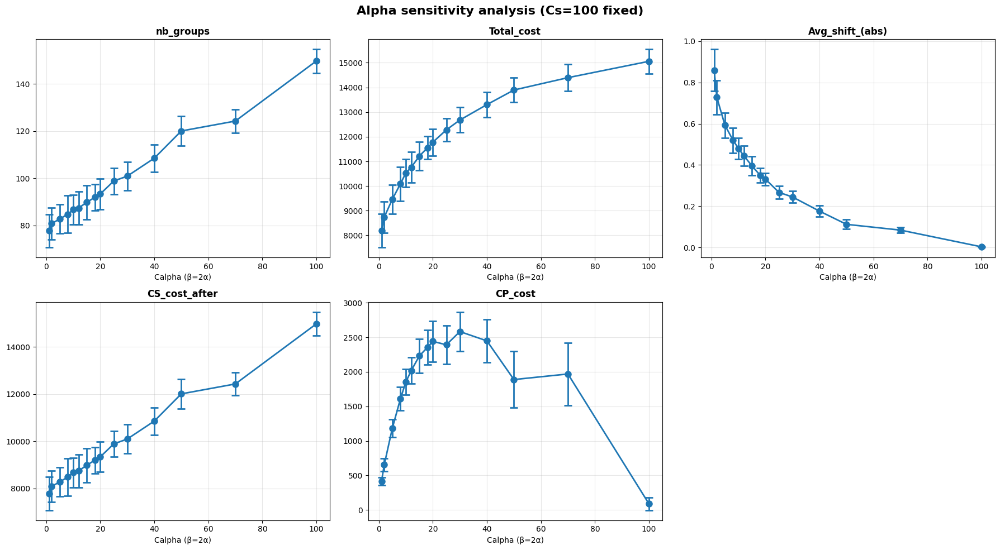

✅ 5指标趋势图已保存：alpha_sensitivity_5metrics.png

📈 快速解读提示：
- nb_groups：聚类点数量，反映调度集中度
- Total_cost：总成本=CS_cost_after + CP_cost
- Avg_shift_(abs)：平均时间偏移，反映调度扰动
- CS_cost_after：聚类后启动成本
- CP_cost：时间惩罚成本


In [19]:
# # 🔥 自动画趋势图
# fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# for i, metric in enumerate(['nb_groups', 'Total_cost', 'Avg_shift_(abs)']):
#     summary = summary_df.groupby('Calpha')[metric].mean()
#     axes[i].plot(summary.index, summary.values, 'o-', linewidth=2)
#     axes[i].set_title(f'{metric} vs alpha (Cs=100 fixed)')
#     axes[i].set_xlabel('Calpha')
#     axes[i].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig('sensitivity_alpha_fixedCs/trends_alpha_fixedCs.png', dpi=300, bbox_inches='tight')
# plt.show()



# 🔥 扩展版画图代码（5个指标：上3下2布局）
# 把这个加到你刚才的敏感性分析脚本末尾

key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 'CS_cost_after', 'CP_cost', 'pct_unchanged_%']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))  # 2行3列，但只用5个
fig.suptitle('Alpha sensitivity analysis (Cs=100 fixed)', fontsize=16, fontweight='bold')

for i, metric in enumerate(key_metrics):
    row = i // 3  # 行索引：0,0,0,1,1
    col = i % 3   # 列索引：0,1,2,0,1
    
    # 计算每个alpha的平均值+std
    summary = summary_df.groupby('Calpha')[metric].agg(['mean', 'std']).reset_index()
    
    # 画均值线 + 误差带 + 散点
    axes[row, col].errorbar(summary['Calpha'], summary['mean'], 
                           yerr=summary['std'], fmt='o-', linewidth=2, 
                           capsize=5, capthick=2, markersize=8, label='mean±std')
    
    axes[row, col].set_title(f'{metric}', fontweight='bold')
    axes[row, col].set_xlabel('Calpha (β=2α)')
    axes[row, col].grid(True, alpha=0.3)
    axes[row, col].tick_params(axis='x', rotation=0)

# 隐藏最后一个空的 subplot
axes[1, 2].set_visible(False)




# 第6个指标：pct_unchanged_%
i=5; metric='pct_unchanged_%'; row=1; col=2
summary = summary_df.groupby('Calpha')[metric].agg(['mean', 'std']).reset_index()
axes[row, col].errorbar(summary['Calpha'], summary['mean'], yerr=summary['std'], 
                       fmt='o-', linewidth=2, capsize=5, markersize=8)
axes[row, col].set_title('pct_unchanged_%', fontweight='bold')
axes[row, col].set_xlabel('Calpha (β=2α)')
axes[row, col].set_ylabel('不变任务比例 %')
axes[row, col].grid(True, alpha=0.3)
# 🔥 关键：加水平参考线 + 注释
axes[row, col].axhline(y=50, color='orange', linestyle='--', alpha=0.7, label='正常水平')
axes[row, col].axhline(y=90, color='red', linestyle=':', alpha=0.8, label='不动阈值')
axes[row, col].legend()


# 调整布局
plt.tight_layout()
plt.subplots_adjust(top=0.92)  # 给总标题留空间

# 🔥 标记异常点
abnormal_alphas = [50, 70, 100]  # 崩溃区
for alpha in abnormal_alphas:
    if alpha in summary['Calpha'].values:
        idx = summary[summary['Calpha']==alpha].index[0]
        axes[row, col].scatter(alpha, summary.loc[idx, 'mean'], 
                                s=200, facecolors='none', 
                                edgecolors='red', linewidth=4, 
                                label='异常区' if i==0 else "")

if i==0:  # 只在第一个图加图例
    axes[row, col].legend()



# 保存高分辨率图
plt.savefig('sensitivity_alpha_fixedCs/alpha_sensitivity_5metrics.png', 
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ 5指标趋势图已保存：alpha_sensitivity_5metrics.png")
print("\n📈 快速解读提示：")
print("- nb_groups：聚类点数量，反映调度集中度")
print("- Total_cost：总成本=CS_cost_after + CP_cost")
print("- Avg_shift_(abs)：平均时间偏移，反映调度扰动")
print("- CS_cost_after：聚类后启动成本")
print("- CP_cost：时间惩罚成本")



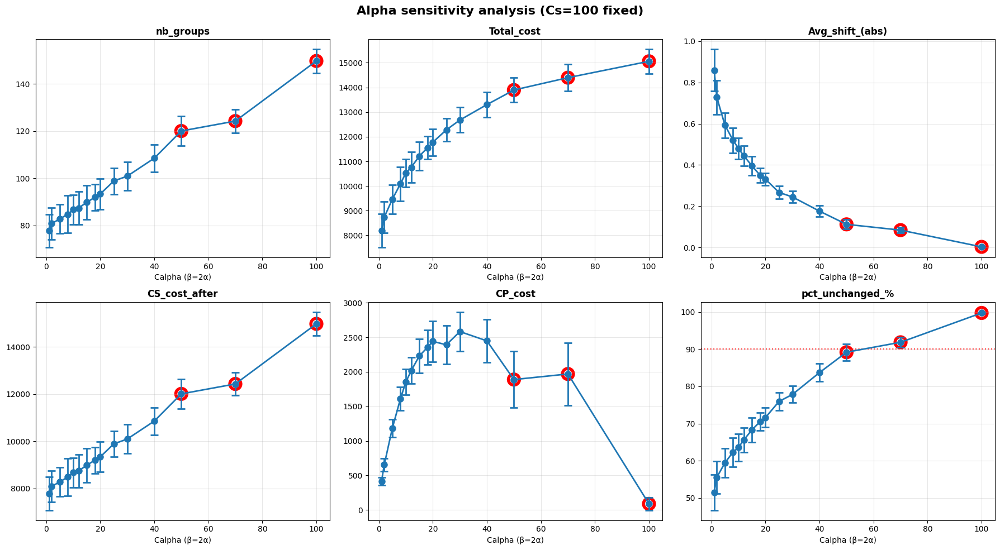

✅ 6指标完整趋势图已保存！


In [25]:
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 
               'CS_cost_after', 'CP_cost', 'pct_unchanged_%']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Alpha sensitivity analysis (Cs=100 fixed)', 
             fontsize=16, fontweight='bold')

# 🔥 异常alpha列表
abnormal_alphas = [50, 70, 100]

for i, metric in enumerate(key_metrics):
    row = i // 3  # 0,0,0,1,1,1
    col = i % 3   # 0,1,2,0,1,2
    
    # 计算summary
    summary = summary_df.groupby('Calpha')[metric].agg(['mean', 'std']).reset_index()
    
    # 画均值线 + 误差带
    axes[row, col].errorbar(summary['Calpha'], summary['mean'], 
                           yerr=summary['std'], fmt='o-', linewidth=2, 
                           capsize=5, capthick=2, markersize=8)
    
    # 🔥 标记异常点
    for alpha in abnormal_alphas:
        if alpha in summary['Calpha'].values:
            idx = summary[summary['Calpha']==alpha].index[0]
            axes[row, col].scatter(alpha, summary.loc[idx, 'mean'], 
                                 s=200, facecolors='none', edgecolors='red', 
                                 linewidth=4)
    
    axes[row, col].set_title(f'{metric}', fontweight='bold')
    axes[row, col].set_xlabel('Calpha (β=2α)')
    axes[row, col].grid(True, alpha=0.3)
    
    # # 🔥 第6图特殊处理：参考线
    if metric == 'pct_unchanged_%':
    #     axes[row, col].axhline(y=50, color='orange', linestyle='--', alpha=0.7, label='normal')
        axes[row, col].axhline(y=90, color='red', linestyle=':', alpha=0.8, label='non-moved')
    #     axes[row, col].legend()
    #     axes[row, col].set_ylabel('Pct non-moved %')

plt.tight_layout()
plt.subplots_adjust(top=0.92)

plt.savefig('sensitivity_alpha_fixedCs/alpha_sensitivity_6metrics.png', 
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ 6指标完整趋势图已保存！")


In [10]:
# 加到你的脚本末尾
cp_summary = summary_df.groupby('Calpha')['CP_cost'].agg(['mean', 'std', 'count'])
print("\nCP_cost 逐组检验：")
for alpha in cp_summary.index:
    group = summary_df[summary_df['Calpha']==alpha]['CP_cost']
    print(f"alpha={alpha}: mean={group.mean():.1f}, std={group.std():.1f}, n={len(group)}")

# 相邻alpha间差异显著性（简化版）
for i in range(len(cp_summary)-1):
    alpha1, alpha2 = cp_summary.index[i], cp_summary.index[i+1]
    t_stat = (cp_summary.loc[alpha1, 'mean'] - cp_summary.loc[alpha2, 'mean']) / \
             np.sqrt(cp_summary.loc[alpha1, 'std']**2/5 + cp_summary.loc[alpha2, 'std']**2/5)
    print(f"alpha {alpha1}→{alpha2}: t-stat={t_stat:.2f} (>2=显著)")



CP_cost 逐组检验：
alpha=1: mean=413.2, std=53.6, n=30
alpha=2: mean=653.0, std=93.2, n=30
alpha=5: mean=1183.2, std=129.3, n=30
alpha=8: mean=1610.7, std=168.1, n=30
alpha=10: mean=1853.7, std=186.0, n=30
alpha=12: mean=2018.4, std=189.5, n=30
alpha=15: mean=2231.0, std=249.3, n=30
alpha=18: mean=2355.6, std=254.1, n=30
alpha=20: mean=2441.3, std=292.8, n=30
alpha=25: mean=2392.5, std=277.5, n=30
alpha=30: mean=2584.0, std=285.1, n=30
alpha=40: mean=2449.3, std=311.2, n=30
alpha=50: mean=1888.3, std=409.5, n=30
alpha=70: mean=1969.3, std=451.3, n=30
alpha=100: mean=86.7, std=93.7, n=30
alpha 1→2: t-stat=-4.98 (>2=显著)
alpha 2→5: t-stat=-7.43 (>2=显著)
alpha 5→8: t-stat=-4.51 (>2=显著)
alpha 8→10: t-stat=-2.17 (>2=显著)
alpha 10→12: t-stat=-1.39 (>2=显著)
alpha 12→15: t-stat=-1.52 (>2=显著)
alpha 15→18: t-stat=-0.78 (>2=显著)
alpha 18→20: t-stat=-0.49 (>2=显著)
alpha 20→25: t-stat=0.27 (>2=显著)
alpha 25→30: t-stat=-1.08 (>2=显著)
alpha 30→40: t-stat=0.71 (>2=显著)
alpha 40→50: t-stat=2.44 (>2=显著)
alpha 50→70:

In [16]:
# 检查α=100是否"不动"
alpha100_data = summary_df[summary_df['Calpha']==100]

print("α=100诊断：")
print(f"Avg_shift_(abs): {alpha100_data['Avg_shift_(abs)'].mean():.3f}")  # 预期≈0
print(f"pct_unchanged_%: {alpha100_data['pct_unchanged_%'].mean():.1f}%")   # 预期≈100%
print(f"nb_groups: {alpha100_data['nb_groups'].mean():.0f}")               # 预期≈原任务数
print(f"CS_cost_after/CS_cost_before: {alpha100_data['CS_cost_after'].mean()/alpha100_data['CS_cost_before'].mean():.2f}")  # 预期≈1.0


α=100诊断：
Avg_shift_(abs): 0.003
pct_unchanged_%: 99.7%
nb_groups: 150
CS_cost_after/CS_cost_before: 0.46


In [27]:
# step 2: Two-factor full-grid experiment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from itertools import product

# 🔥 基础参数（从第一阶段继承）
BASE_PARAMS = {
    'P': 100, 'T': 180, 'Cmax': 10, 'window_size': 10, 
    'advanced': 3, 'K': 5.993, 'x_days': 3
}

# 🔥 第二阶段：两因子网格
alpha_grid = [2, 8, 15]      # 第一阶段验证的安全区间
cs_grid = [50, 100, 200]     # 启动成本三档
seeds = list(range(1, 31))   # 30 seeds

os.makedirs('stage2_alpha_cs_grid', exist_ok=True)

all_grid_results = []

print("🔄 第二阶段：α × Cs 网格实验")
print(f"设计：{len(alpha_grid)} α × {len(cs_grid)} Cs × {len(seeds)} seeds = {len(alpha_grid)*len(cs_grid)*len(seeds)} 总运行")

for alpha, cs in product(alpha_grid, cs_grid):
    print(f"\n--- α={alpha}, Cs={cs} ---")
    
    params = BASE_PARAMS.copy()
    params['Calpha'] = alpha
    params['Cbeta'] = 2 * alpha
    params['Cs'] = cs
    
    filename = f"stage2_alpha_cs_grid/alpha{alpha}_cs{cs}.csv"
    result_df = run_analysis_with_csv_export(params, seeds, filename)
    
    # 加参数列
    result_df['Calpha'] = alpha
    result_df['Cs'] = cs
    
    all_grid_results.append(result_df)

# 🔥 大汇总表
grid_summary = pd.concat(all_grid_results, ignore_index=True)
grid_summary.to_csv('stage2_alpha_cs_grid/grid_full_summary.csv', index=False)
print("\n✅ 第二阶段汇总完成！")


🔄 第二阶段：α × Cs 网格实验
设计：3 α × 3 Cs × 30 seeds = 270 总运行

--- α=2, Cs=50 ---

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 10.00        ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 10.00        ...
9          ... 10.00        ...
10         4          [36, 36]             36.

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 60: N_tasks=13
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 356 rows, 165 columns and 1107 nonzeros
Model fingerprint: 0x41e06385
Variable types: 11 continuous, 154 integer (154 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Found heuristic solution: objective 24.0000000
Presolve removed 321 rows and 30 columns
Presolve time: 0.00s
Presolved: 35 rows, 135 columns, 394 nonzeros
Variable types: 0 continuous, 135 integer (135 binary)
Found heuristic solution: objective 134.0000000

Root relaxation: objective 5.844444e+02, 13 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexp

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)


Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 130: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 140: N_tasks=12
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 331 rows, 154 columns and 1022 nonzeros
Model fingerprint: 0xcb09ce96
Variable types: 11 continuous, 143 integer (143 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective 30.0000000
Presolve removed 297 rows and 29 columns
Presolve time: 0.00s
Presolved: 34 ro

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (1,460 outputs left out)

Model stats: 363 vars, 790 cons
Objective value: 5025.0
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 70: N_tasks=16
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 429 rows, 198 columns and 1342 nonzeros
Model fingerprint: 0x1333fef2
Variable types: 11 continuous, 187 integer (187 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Presolve removed 371 rows and 51 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 70: 3
Set param

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 130: N_tasks=21
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 558 rows, 253 columns and 1807 nonzeros
Model fingerprint: 0x97ad41fb
Variable types: 11 continuous, 242 integer (242 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+01, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective 1160.0000000
Presolve removed 515 rows and 60 columns
Presolve time: 0.00s
Presolved: 43 rows, 193 columns, 568 nonzeros
Variable types: 0 continuous, 193 integer (193 binary)
Found heuristic solution: objective 2405.0000000

Root relaxation: objective 3.780000e+03, 21 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl U

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/3045617426.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


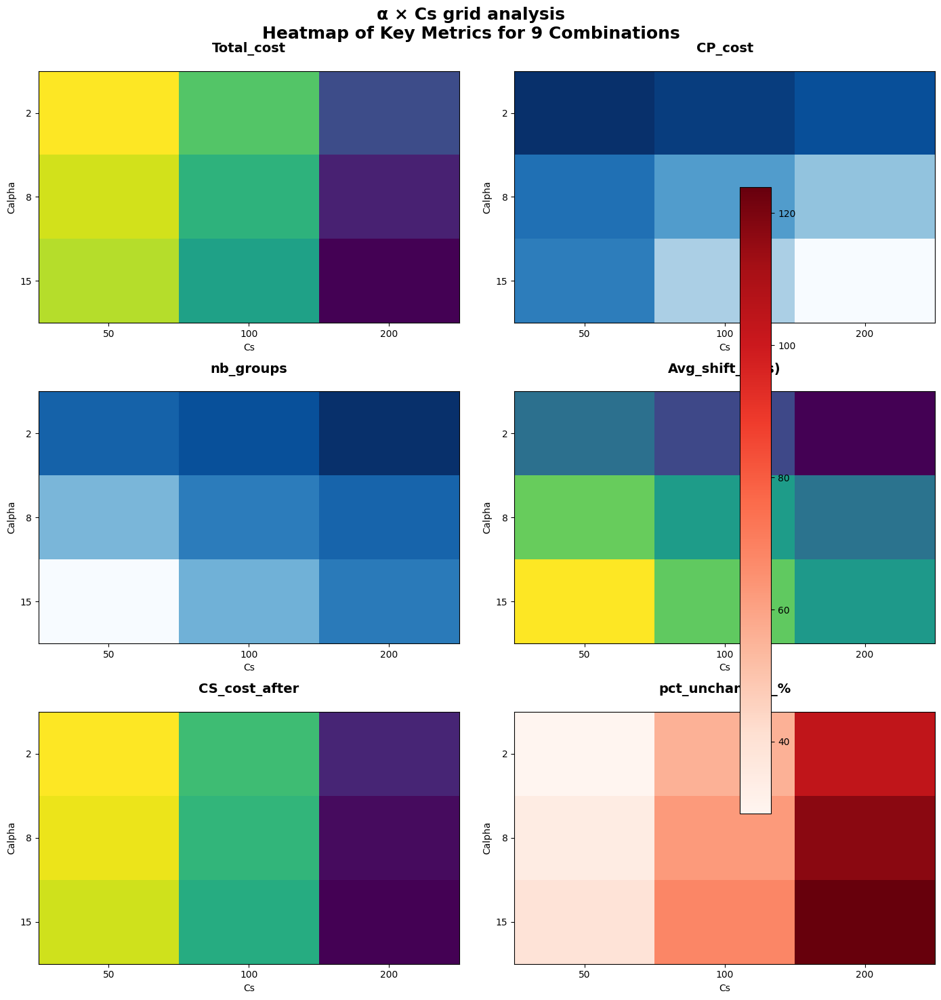


🏆 9 Combinations Total_cost Ranking：
   Calpha   Cs  Total_cost  CP_cost  nb_groups  rank
0       2   50      4641.0    518.0       82.0   1.0
3       8   50      5665.0   1150.0       90.0   2.0
6      15   50      6330.0   1284.0      101.0   3.0
1       2  100      8736.0    653.0       81.0   4.0
4       8  100     10091.0   1611.0       85.0   5.0
7      15  100     11214.0   2231.0       90.0   6.0
2       2  200     16433.0    826.0       78.0   7.0
5       8  200     18576.0   2049.0       83.0   8.0
8      15  200     20008.0   3088.0       85.0   9.0

🌟 Best：α=2.0, Cs=50, Total_cost=4641

📊 Most stable（std min）：α=15, Cs=50


In [35]:
# 🔥 修复版：3行2列布局（6个指标完美）
key_metrics = ['Total_cost', 'CP_cost', 'nb_groups', 
               'Avg_shift_(abs)', 'CS_cost_after', 'pct_unchanged_%']

fig, axes = plt.subplots(3, 2, figsize=(14, 15))  # 🔥 3行2列=6个
fig.suptitle('α × Cs grid analysis\nHeatmap of Key Metrics for 9 Combinations', fontsize=18, fontweight='bold')

alpha_grid = [2, 8, 15]
cs_grid = [50, 100, 200]

for i, metric in enumerate(key_metrics):
    row = i // 2  # 0,0,1,1,2,2
    col = i % 2   # 0,1,0,1,0,1
    
    # 🔥 pivot_table生成热图数据
    pivot = grid_summary.pivot_table(
        values=metric, index='Calpha', columns='Cs', aggfunc='mean'
    ).reindex(index=alpha_grid, columns=cs_grid)  # 确保顺序
    
    # 🔥 智能colormap
    if metric in ['pct_unchanged_%']:
        cmap = 'Reds'      # 高值红色（不动=坏）
    elif metric in ['nb_groups', 'CP_cost']:
        cmap = 'Blues_r'   # 高值深蓝（成本高=坏）
    else:
        cmap = 'viridis_r' # 低值绿色（成本低=好）
    
    im = axes[row, col].imshow(pivot.values, cmap=cmap, aspect='auto', vmin=pivot.min().min(), vmax=pivot.max().max())
    
    axes[row, col].set_title(f'{metric}', fontsize=14, fontweight='bold', pad=20)
    axes[row, col].set_xticks(range(len(cs_grid)))
    axes[row, col].set_yticks(range(len(alpha_grid)))
    axes[row, col].set_xticklabels(cs_grid)
    axes[row, col].set_yticklabels(alpha_grid)
    axes[row, col].set_xlabel('Cs')
    axes[row, col].set_ylabel('Calpha')

# 🔥 统一colorbar
fig.colorbar(im, ax=axes, shrink=0.8, location='right')

plt.tight_layout()
plt.savefig('stage2_alpha_cs_grid/heatmap_9combinations_fixed.png', dpi=300, bbox_inches='tight')
plt.show()

# 🔥 性能排名表
performance = grid_summary.groupby(['Calpha', 'Cs'])[['Total_cost', 'CP_cost', 'nb_groups']].mean().reset_index()
performance['rank'] = performance['Total_cost'].rank(method='min')
performance = performance.sort_values('rank')

print("\n🏆 9 Combinations Total_cost Ranking：")
print(performance.round(0))
print(f"\n🌟 Best：α={performance.iloc[0]['Calpha']}, Cs={performance.iloc[0]['Cs']:.0f}, Total_cost={performance.iloc[0]['Total_cost']:.0f}")

# 🔥 稳定性检查
stability = grid_summary.groupby(['Calpha', 'Cs'])['Total_cost'].std().reset_index()
print(f"\n📊 Most stable（std min）：α={stability.loc[stability['Total_cost'].idxmin(), 'Calpha']}, Cs={stability.loc[stability['Total_cost'].idxmin(), 'Cs']:.0f}")


In [38]:
# 网格更精细版
import numpy as np
from itertools import product

# 🔥 精细网格
fine_alpha = np.arange(5, 11, 1).tolist()      # [5,6,7,8,9,10]
fine_cs = np.arange(75, 127.5, 12.5).tolist()  # [75,87.5,100,112.5,125]

print(f"精细网格：{len(fine_alpha)} α × {len(fine_cs)} Cs = {len(fine_alpha)*len(fine_cs)} 组")

os.makedirs('stage3_fine_grid', exist_ok=True)

fine_results = []

for alpha, cs in product(fine_alpha, fine_cs):
    print(f"精细网格：α={alpha}, Cs={cs:.1f}")
    
    params = BASE_PARAMS.copy()
    params['Calpha'] = alpha
    params['Cbeta'] = 2 * alpha
    params['Cs'] = cs
    
    filename = f"stage3_fine_grid/alpha{alpha}_cs{cs:.1f}.csv"
    result_df = run_analysis_with_csv_export(params, seeds[:20], filename)  # 20 seeds加速
    
    result_df['Calpha'] = alpha
    result_df['Cs'] = cs
    fine_results.append(result_df)

# 大汇总
fine_summary = pd.concat(fine_results, ignore_index=True)
fine_summary.to_csv('stage3_fine_grid/fine_grid_full.csv', index=False)


精细网格：6 α × 5 Cs = 30 组
精细网格：α=5, Cs=75.0

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 10.00        ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 10.00        ...
9          ... 10.00        ...
10         4          [36, 36]             36.00        22         51        
1

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 70: N_tasks=19
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 504 rows, 231 columns and 1597 nonzeros
Model fingerprint: 0x272fd0a7
Variable types: 11 continuous, 220 integer (220 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [5e+00, 8e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+01]
Presolve removed 438 rows and 62 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 70: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to va

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

H    0     0                    1415.0000000 1467.69231  3.72%     -    0s

Cutting planes:
  Cover: 19
  Clique: 21
  MIR: 10
  Zero half: 1

Explored 1 nodes (78 simplex iterations) in 0.01 seconds (0.01 work units)
Thread count was 12 (of 12 available processors)

Solution count 7: 1415 1375 1260 ... 515

Optimal solution found (tolerance 5.00e-02)
Best objective 1.415000000000e+03, best bound 1.465000000000e+03, gap 3.5336%
Model stats: 286 vars, 631 cons
Objective value: 1415.0
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 140: N_tasks=12
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 331 rows, 154 columns and 1022 nonzeros
Model fingerprint: 0x4c2243e6
Variable types: 11 continuous, 143 integer (143 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Object

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (3,481 outputs left out)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 631 rows, 286 columns and 2042 nonzeros
Model fingerprint: 0x6f142690
Variable types: 11 continuous, 275 integer (275 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [5e+00, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective 710.0000000
Presolve removed 585 rows and 86 columns
Presolve time: 0.00s
Presolved: 46 rows, 200 columns, 589 nonzeros
Variable types: 0 continuous, 200 integer (200 binary)
Found heuristic solution: objective 1785.0000000

Root relaxation: objective 2.695833e+03, 24 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 2695.83333  

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

✅ Seed 20: CP_cost=2090.0, Groups=69

📁 完整结果已保存到: stage3_fine_grid/alpha10_cs125.0.csv
📊 包含 20 种子, 19 个指标列


/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/2721192144.py:17: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  pivot_total = fine_summary.pivot_table(values='Total_cost', index='Calpha_r', columns='Cs_r', aggfunc='mean').fillna(method='ffill')
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/2721192144.py:64: UserWarning: Glyph 31934 (\N{CJK UNIFIED IDEOGRAPH-7CBE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/2721192144.py:64: UserWarning: Glyph 32454 (\N{CJK UNIFIED IDEOGRAPH-7EC6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_38299/2721192144.py:64: UserWarning: Glyph 32593 (\N{CJK UNIFIED IDEOGRAPH-7F51}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel

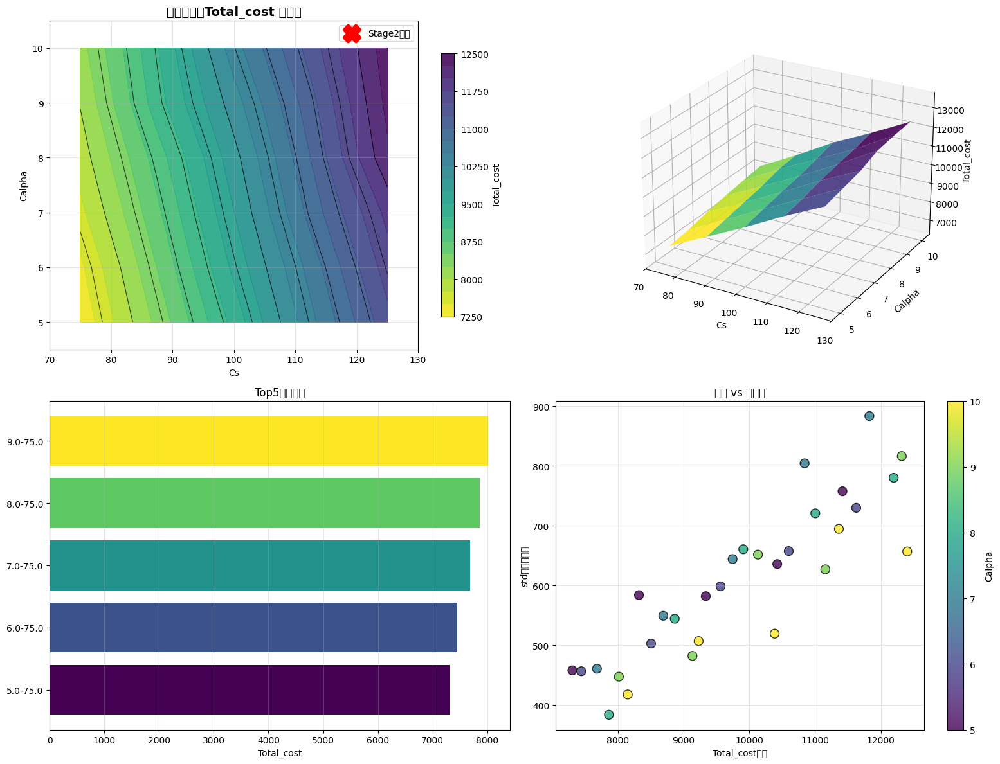


🎯 全局最优参数：
  Calpha = 5.0
  Cbeta  = 10.0
  Cs     = 75.0
  Total_cost = 6290
  seed = 20.0

🏆 Top3推荐：
 Calpha   Cs  Total_cost  nb_groups  seed
      5 75.0      6290.0         68    20
      6 75.0      6429.0         69    20
      7 75.0      6669.0         71    20


In [44]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# 🔥 预处理（修复Cbeta）
fine_summary = fine_summary.copy()
fine_summary['Cbeta'] = 2 * fine_summary['Calpha']  # 🔥 动态生成
fine_summary['Calpha_r'] = fine_summary['Calpha'].round(1)
fine_summary['Cs_r'] = fine_summary['Cs'].round(1)

# 🔥 数据范围
alpha_range = sorted(fine_summary['Calpha'].unique())
cs_range = sorted(fine_summary['Cs'].unique())
total_range = fine_summary['Total_cost'].agg(['min', 'max'])

# 🔥 pivot（安全处理）
pivot_total = fine_summary.pivot_table(values='Total_cost', index='Calpha_r', columns='Cs_r', aggfunc='mean').fillna(method='ffill')

plt.figure(figsize=(16, 12))

# 🔥 1. 等高线图
plt.subplot(2, 2, 1)
X, Y = np.meshgrid(cs_range, alpha_range)
data = pivot_total.reindex(index=alpha_range, columns=cs_range, fill_value=np.nan)
contour = plt.contourf(X, Y, data.values, levels=20, cmap='viridis_r', alpha=0.9)
plt.contour(X, Y, data.values, colors='black', linewidths=0.8, levels=15, alpha=0.7)
plt.colorbar(contour, label='Total_cost', shrink=0.8)
plt.scatter(8, 100, c='red', s=300, marker='X', linewidth=4, zorder=10, label='Stage2最优')
plt.xlim(min(cs_range)-5, max(cs_range)+5)
plt.ylim(min(alpha_range)-0.5, max(alpha_range)+0.5)
plt.xlabel('Cs'); plt.ylabel('Calpha')
plt.title('精细网格：Total_cost 等高线', fontsize=14, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)

# 🔥 2. 3D表面
ax = plt.subplot(2, 2, 2, projection='3d')
surf = ax.plot_surface(X, Y, data.values, cmap='viridis_r', alpha=0.9, linewidth=0)
ax.scatter([8], [100], [pivot_total.loc[8.0,100.0] if 8.0 in pivot_total.index and 100.0 in pivot_total.columns else np.nan], 
          c='red', s=200, marker='X')
ax.set_xlim(min(cs_range)-5, max(cs_range)+5)
ax.set_ylim(min(alpha_range)-0.5, max(alpha_range)+0.5)
ax.set_zlim(total_range['min']-50, total_range['max']+50)
ax.set_xlabel('Cs'); ax.set_ylabel('Calpha'); ax.set_zlabel('Total_cost')
ax.view_init(elev=25, azim=-60)

# 🔥 3. Top5排名
plt.subplot(2, 2, 3)
performance = fine_summary.groupby(['Calpha_r', 'Cs_r'])['Total_cost'].mean().reset_index()
performance['label'] = performance['Calpha_r'].map('{:.1f}'.format) + '-' + performance['Cs_r'].map('{:.1f}'.format)
top5 = performance.nsmallest(5, 'Total_cost')
colors = plt.cm.viridis(np.linspace(0, 1, 5))
plt.barh(range(5), top5['Total_cost'], color=colors)
plt.yticks(range(5), top5['label'])
plt.xlabel('Total_cost'); plt.title('Top5最优组合'); plt.grid(axis='x', alpha=0.3)

# 🔥 4. 稳定性散点
plt.subplot(2, 2, 4)
stability = fine_summary.groupby(['Calpha_r', 'Cs_r']).agg({'Total_cost': ['mean', 'std']}).reset_index()
plt.scatter(stability[('Total_cost', 'mean')], stability[('Total_cost', 'std')], 
           c=stability['Calpha_r'], cmap='viridis', s=100, alpha=0.8, edgecolors='black')
plt.xlabel('Total_cost均值'); plt.ylabel('std（稳定性）')
plt.title('性能 vs 稳定性'); plt.grid(True, alpha=0.3); plt.colorbar(label='Calpha')

plt.tight_layout()
plt.savefig('stage3_fine_grid/FINAL_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# 🔥 5. 最终推荐（安全版）
best_idx = fine_summary['Total_cost'].idxmin()
best = fine_summary.loc[best_idx]
print(f"\n🎯 全局最优参数：")
print(f"  Calpha = {best['Calpha']:.1f}")
print(f"  Cbeta  = {best['Cbeta']:.1f}")
print(f"  Cs     = {best['Cs']:.1f}")
print(f"  Total_cost = {best['Total_cost']:.0f}")
print(f"  seed = {best['seed']}")

# 🔥 Top3
top3_mask = fine_summary['Total_cost'].nsmallest(3).index
top3 = fine_summary.loc[top3_mask][['Calpha', 'Cs', 'Total_cost', 'nb_groups', 'seed']].round(1)
print(f"\n🏆 Top3推荐：")
print(top3.to_string(index=False))
